In [4]:
import json, hashlib, shutil, random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

In [5]:
SEED = 42
SRC_ROOT = Path.home() / "datasets" / "IQ-OTHNCCD"
DST = Path("../data")
EXTS = {".jpg", ".jpeg", ".png"}
random.seed(SEED)
np.random.seed(SEED)

In [6]:
def class_of(folder_name: str):
    n = folder_name.lower()
    if "ben" in n:   return "benign"     
    if "malig" in n: return "malignant"
    if "normal" in n: return "normal"
    return None
    
print(class_of("bengin_cases"))
print(class_of("Malignant cases"))
print(class_of("Normal cases"))    
print(class_of("Test cases"))               
    


records = []
for d in SRC_ROOT.rglob("*"):
    if d.is_dir():
        cls = class_of(d.name)
        if cls is None:
            continue
        for f in d.iterdir():
            if f.is_file() and f.suffix.lower() in EXTS:
                records.append({"path": str(f), "class": cls})

df = pd.DataFrame(records)
assert len(df) > 0, "no pic found"
print( ":before removing duplicates\n", df["class"].value_counts(), "\n")

benign
malignant
normal
None
:before removing duplicates
 class
malignant    561
normal       416
benign       120
Name: count, dtype: int64 



In [7]:
def md5(p):
    return hashlib.md5(Path(p).read_bytes()).hexdigest()

df["md5"] = df["path"].apply(md5)
dups = df[df.duplicated("md5", keep="first")]
print(f"removed dups numbers: {len(dups)}")
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)


sizes, modes = Counter(), Counter()
for p in df["path"]:
    with Image.open(p) as im:
        sizes[im.size] += 1
        modes[im.mode] += 1
print("\n scales:", sizes.most_common(5))
print("colors :", dict(modes))


removed dups numbers: 43

 scales: [((512, 512), 993), ((623, 512), 31), ((801, 512), 28), ((511, 404), 1), ((506, 331), 1)]
colors : {'RGB': 1054}


In [8]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["class"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["class"], random_state=SEED)

train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")
all_df = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)
all_df.sample(10, random_state=42)

,path,class,md5,split
260,/home/negino/datasets/IQ-OTHNCCD/Bengin cases/...,benign,8d0e3e5e7645465ec0e805cd99f36ba5,train
1025,/home/negino/datasets/IQ-OTHNCCD/Malignant cas...,malignant,ca9551a8975bbd84b05daf4d6f52c893,test
845,/home/negino/datasets/IQ-OTHNCCD/Normal cases/...,normal,9fe280651d19662b526a68a7a9cdcf74,val
1005,/home/negino/datasets/IQ-OTHNCCD/Normal cases/...,normal,b4d9ba835ae0cf910be46cce875396e4,test
88,/home/negino/datasets/IQ-OTHNCCD/Normal cases/...,normal,751f223793f27ad6752e79f82a384ac2,train
457,/home/negino/datasets/IQ-OTHNCCD/Normal cases/...,normal,332744236e00fd1f62a65d04b78820de,train
184,/home/negino/datasets/IQ-OTHNCCD/Malignant cas...,malignant,b529656f1f341e993f2600c8937fdb79,train
986,/home/negino/datasets/IQ-OTHNCCD/Malignant cas...,malignant,bdf83d479a5da9672d03bd2025a63c26,test
367,/home/negino/datasets/IQ-OTHNCCD/Malignant cas...,malignant,2484aae85bd32df8ef69061f633328fb,train
558,/home/negino/datasets/IQ-OTHNCCD/Normal cases/...,normal,006e50add470316a5d1a7fff11de337b,train


In [9]:
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    A = set(all_df[all_df.split == a]["md5"]); B = set(all_df[all_df.split == b]["md5"])
    assert not (A & B), f"OVERLAP NETWEEN{a} و {b}!"
print("\n NO DATA LEAKAGE FOUND")



 NO DATA LEAKAGE FOUND


In [10]:
for i, (_, r) in enumerate(all_df.iterrows()):
    if i % 100 == 0:
        print(f"  {i}/{len(all_df)}")
    
    out = DST / r["split"] / r["class"]
    out.mkdir(parents=True, exist_ok=True)
    
    src = Path(r["path"])
    dst_file = out / f"{r['md5'][:8]}_{src.name}"
    
    try:
        shutil.copy(src, dst_file)
    except Exception as e:
        print(f" eror: {src} → {e}")

all_df.to_csv("../split_manifest.csv", index=False)

  0/1054
  100/1054
  200/1054
  300/1054
  400/1054
  500/1054
  600/1054
  700/1054
  800/1054
  900/1054
  1000/1054


In [11]:
all_df.to_csv("split_manifest.csv", index=False)



In [15]:

table = pd.crosstab(all_df["class"], all_df["split"], margins=True)[["train", "val", "test", "All"]]
print(table)


split      train  val  test   All
class                            
benign        71   15    16   102
malignant    383   82    82   547
normal       283   61    61   405
All          737  158   159  1054


In [13]:
print((pd.crosstab(all_df["split"], all_df["class"], normalize="index") * 100).round(1))

class  benign  malignant  normal
split                           
test     10.1       51.6    38.4
train     9.6       52.0    38.4
val       9.5       51.9    38.6


In [17]:
classes = sorted(train_df["class"].unique())
counts = train_df["class"].value_counts()
weights = {c: float(len(train_df) / (len(classes) * counts[c])) for c in classes}
json.dump({"classes": classes, "weights": weights}, open("class_weights.json", "w"), indent=2)


for c, w in weights.items():
    print(f"  {c}: {w:.3f}")

  benign: 3.460
  malignant: 0.641
  normal: 0.868


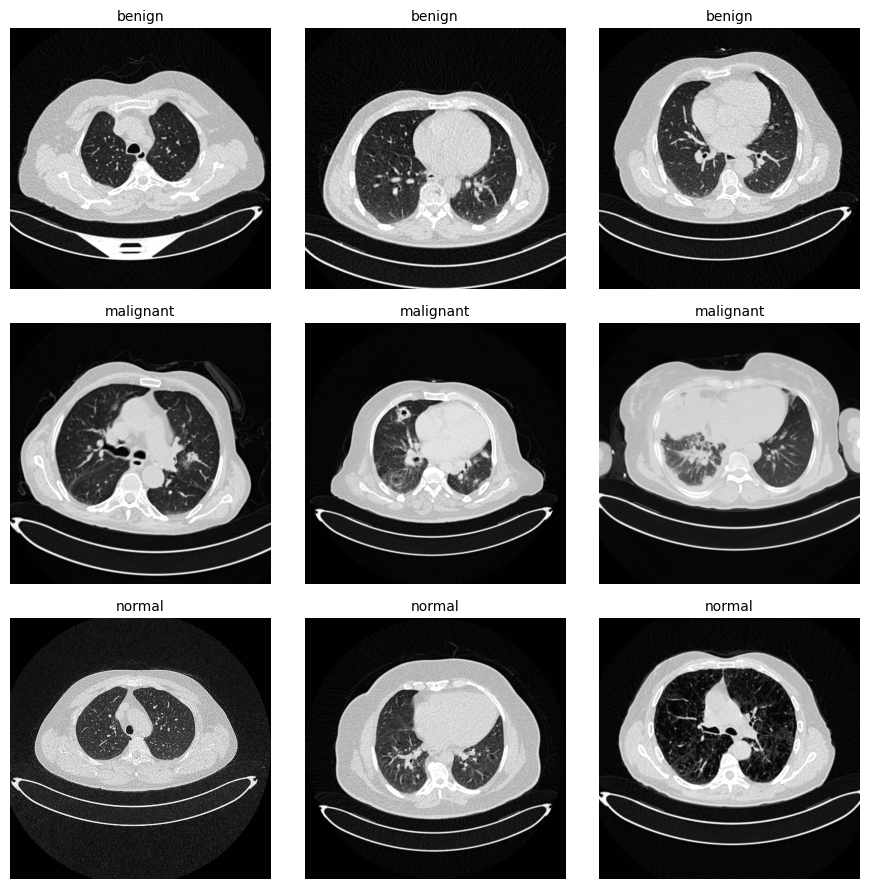

In [19]:

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for i, c in enumerate(classes):
    samples = train_df[train_df["class"] == c].sample(min(3, len(train_df[train_df["class"] == c])), random_state=SEED)["path"]
    for j, p in enumerate(samples):
        try:
            axes[i, j].imshow(Image.open(p).convert("L"), cmap="gray")
            axes[i, j].set_title(c, fontsize=10)
        except:
            axes[i, j].text(0.5, 0.5, "error", ha="center", va="center")
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig("samples.png", dpi=150)
plt.show()
